In [1]:
# TODO 1: define more categorical features, e.g. all combinations for   (you'll see that September is actually an important dummy in one of the models)
# TODO 2: find more "hand rules" - can get it from decision trees important factors, or randomly build on other most popular macro/tech indicators/ manual_features
     




In [2]:
import pandas as pd
import numpy as np
import yfinance as yf
import pandas_datareader as pdr
import plotly.graph_objs as go
import plotly.graph_objects as go
import plotly.express as px
import time
from datetime import date
import gdown
import requests
from io import StringIO
from tqdm.notebook import tqdm
import talib
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
from math import sqrt
import matplotlib.pyplot as plt
     

In [3]:
df_full = pd.read_parquet("/Users/Blackmanking/stocks/stocks_df_combined_2026_11_16.parquet.brotli",)

In [4]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
Index: 238392 entries, 0 to 6052
Columns: 204 entries, Open to growth_btc_usd_365d
dtypes: datetime64[ns](3), float64(130), int32(64), int64(5), object(2)
memory usage: 314.7+ MB


In [5]:
df_full.head()

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,growth_brent_oil_7d,growth_brent_oil_30d,growth_brent_oil_90d,growth_brent_oil_365d,growth_btc_usd_1d,growth_btc_usd_3d,growth_btc_usd_7d,growth_btc_usd_30d,growth_btc_usd_90d,growth_btc_usd_365d
0,0.053745,0.061649,0.053745,0.059014,1.031789e+09,0.0,0.0,MSFT,1986,1986-03-01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.059014,0.062176,0.059014,0.061122,3.081600e+08,0.0,0.0,MSFT,1986,1986-03-01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.061122,0.062703,0.061122,0.062176,1.331712e+08,0.0,0.0,MSFT,1986,1986-03-01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.062176,0.062703,0.060068,0.060595,6.776640e+07,0.0,0.0,MSFT,1986,1986-03-01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.060595,0.061122,0.059014,0.059541,4.789440e+07,0.0,0.0,MSFT,1986,1986-03-01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df_full.keys()

Index(['Open', 'High', 'Low', 'Close_x', 'Volume', 'Dividends', 'Stock Splits',
       'Ticker', 'Year', 'Month',
       ...
       'growth_brent_oil_7d', 'growth_brent_oil_30d', 'growth_brent_oil_90d',
       'growth_brent_oil_365d', 'growth_btc_usd_1d', 'growth_btc_usd_3d',
       'growth_btc_usd_7d', 'growth_btc_usd_30d', 'growth_btc_usd_90d',
       'growth_btc_usd_365d'],
      dtype='object', length=204)

In [7]:
GROWTH = [g for g in df_full.keys() if (g.find('growth_') == 0)&(g.find('future')<0)]
GROWTH

['growth_1d',
 'growth_3d',
 'growth_7d',
 'growth_30d',
 'growth_90d',
 'growth_365d',
 'growth_dax_1d',
 'growth_dax_3d',
 'growth_dax_7d',
 'growth_dax_30d',
 'growth_dax_90d',
 'growth_dax_365d',
 'growth_snp500_1d',
 'growth_snp500_3d',
 'growth_snp500_7d',
 'growth_snp500_30d',
 'growth_snp500_90d',
 'growth_snp500_365d',
 'growth_dji_1d',
 'growth_dji_3d',
 'growth_dji_7d',
 'growth_dji_30d',
 'growth_dji_90d',
 'growth_dji_365d',
 'growth_epi_1d',
 'growth_epi_3d',
 'growth_epi_7d',
 'growth_epi_30d',
 'growth_epi_90d',
 'growth_epi_365d',
 'growth_gold_1d',
 'growth_gold_3d',
 'growth_gold_7d',
 'growth_gold_30d',
 'growth_gold_90d',
 'growth_gold_365d',
 'growth_wti_oil_1d',
 'growth_wti_oil_3d',
 'growth_wti_oil_7d',
 'growth_wti_oil_30d',
 'growth_wti_oil_90d',
 'growth_wti_oil_365d',
 'growth_brent_oil_1d',
 'growth_brent_oil_3d',
 'growth_brent_oil_7d',
 'growth_brent_oil_30d',
 'growth_brent_oil_90d',
 'growth_brent_oil_365d',
 'growth_btc_usd_1d',
 'growth_btc_usd_3d',


In [8]:
OHLCV = ['Open','High','Low','Close','Adj Close_x','Volume']

In [9]:
CATEGORICAL = ['Month','Weekday','Ticker','ticker_type']

In [10]:
TO_PREDICT = [g for g in df_full.keys() if (g.find('future')>= 0)]
TO_PREDICT

['growth_future_30d', 'is_positive_growth_30d_future']

In [11]:
TO_DROP = ['Year','Date','index_x','index_y','index','Quarter','Adj Close_y'] + CATEGORICAL + OHLCV
TO_DROP

['Year',
 'Date',
 'index_x',
 'index_y',
 'index',
 'Quarter',
 'Adj Close_y',
 'Month',
 'Weekday',
 'Ticker',
 'ticker_type',
 'Open',
 'High',
 'Low',
 'Close',
 'Adj Close_x',
 'Volume']

In [12]:
#to avoid divide by zero
df_full['ln_volume'] = df_full.Volume.replace(0,np.nan).fillna(1e-9).apply(lambda x:np.log(x))

In [13]:
#Manually defined features
CUSTOM_NUMERICAL = ['SMA10','SMA20','growing_moving_average','high_minus_low_relative','Volatility','ln_volume']

In [14]:
# All Supported Ta-lib indicators: https://github.com/TA-Lib/ta-lib-python/blob/master/docs/funcs.md

TECHNICAL_INDICATORS = ['adx', 'adxr', 'apo', 'aroon_1','aroon_2', 'aroonosc',
 'bop', 'cci', 'cmo','dx', 'macd', 'macdsignal', 'macdhist', 'macd_ext',
 'macdsignal_ext', 'macdhist_ext', 'macd_fix', 'macdsignal_fix',
 'macdhist_fix', 'mfi', 'minus_di', 'mom', 'plus_di', 'dm', 'ppo',
 'roc', 'rocp', 'rocr', 'rocr100', 'rsi', 'slowk', 'slowd', 'fastk',
 'fastd', 'fastk_rsi', 'fastd_rsi', 'trix', 'ultosc', 'willr',
 'ad', 'adosc', 'obv', 'atr', 'natr', 'ht_dcperiod', 'ht_dcphase',
 'ht_phasor_inphase', 'ht_phasor_quadrature', 'ht_sine_sine', 'ht_sine_leadsine',
 'ht_trendmod', 'avgprice', 'medprice', 'typprice', 'wclprice']

In [15]:
TECHNICAL_PATTERNS = [g for g in df_full.keys() if g.find('cdl')>=0]
print(f'Technical patterns count = {len(TECHNICAL_PATTERNS)}, examples = {TECHNICAL_PATTERNS[0:5]}')

Technical patterns count = 61, examples = ['cdl2crows', 'cdl3blackrows', 'cdl3inside', 'cdl3linestrike', 'cdl3outside']


In [16]:
MACRO = ['gdppot_us_yoy', 'gdppot_us_qoq', 'cpi_core_yoy', 'cpi_core_mom', 'FEDFUNDS',
 'DGS1', 'DGS5', 'DGS10']

In [17]:
NUMERICAL = GROWTH + TECHNICAL_INDICATORS + TECHNICAL_PATTERNS + CUSTOM_NUMERICAL + MACRO

In [18]:
# CHECK: NO OTHER INDICATORS LEFT
OTHER = [k for k in df_full.keys() if k not in OHLCV + CATEGORICAL + NUMERICAL + TO_DROP + TO_PREDICT]
OTHER

['Close_x', 'Dividends', 'Stock Splits', 'Adj Close', 'Close_y']

In [19]:
df_full.Ticker.nunique()

32

In [20]:
# tickers, min-max date, count of daily observations
df_full.groupby(['Ticker'])['Date'].agg(['min','max','count'])

,min,max,count
Ticker,,,
AAPL,1980-12-12,2026-11-13,11574
ACN,2001-07-19,2026-11-13,6369
AMZN,1997-05-15,2026-11-13,7422
ASML,1995-03-15,2026-11-13,7971
AVGO,2009-08-06,2026-11-13,4346
BHARTIARTL.NS,2002-07-01,2026-11-16,6050
BRK-B,1996-05-09,2026-11-13,7679
CDI.PA,1992-01-27,2026-11-13,8974
GOOG,2004-08-19,2026-11-13,5596


In [21]:
# truncated df_full with 25 years of data (and defined growth variables)
df = df_full[df_full.Date>='2000-01-01']
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199925 entries, 3490 to 6052
Columns: 205 entries, Open to ln_volume
dtypes: datetime64[ns](3), float64(131), int32(64), int64(5), object(2)
memory usage: 265.4+ MB


In [22]:
# let's look at the features count and df size:
df[NUMERICAL].info()

<class 'pandas.core.frame.DataFrame'>
Index: 199925 entries, 3490 to 6052
Columns: 184 entries, growth_1d to DGS10
dtypes: float64(121), int32(62), int64(1)
memory usage: 234.9 MB


In [23]:
#GENERATING DUMMIES
# WHAT ARE THE CATEGORICAL VARIABLES
CATEGORICAL

['Month', 'Weekday', 'Ticker', 'ticker_type']

In [24]:
#WE WANT TO CONVERT TO STRINGS SO GET_DUMMIES CREATES DUMMY COLUMNS PROPERLY
df['Weekday'] = df['Weekday'].astype(str)
df['Month'] = df['Month'].dt.month.astype(str)

/var/folders/2d/1c91gggs08n6vxd8g4bhwqmc0001yj/T/ipykernel_77827/4001567700.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Weekday'] = df['Weekday'].astype(str)
/var/folders/2d/1c91gggs08n6vxd8g4bhwqmc0001yj/T/ipykernel_77827/4001567700.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Month'] = df['Month'].dt.month.astype(str)


In [25]:
#generating dummy variables(no need for bool and let us have int32 for that reason) 
dummy_variables = pd.get_dummies(df[CATEGORICAL],dtype ='int32')

In [26]:
dummy_variables.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199925 entries, 3490 to 6052
Data columns (total 54 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Month_1               199925 non-null  int32
 1   Month_10              199925 non-null  int32
 2   Month_11              199925 non-null  int32
 3   Month_12              199925 non-null  int32
 4   Month_2               199925 non-null  int32
 5   Month_3               199925 non-null  int32
 6   Month_4               199925 non-null  int32
 7   Month_5               199925 non-null  int32
 8   Month_6               199925 non-null  int32
 9   Month_7               199925 non-null  int32
 10  Month_8               199925 non-null  int32
 11  Month_9               199925 non-null  int32
 12  Weekday_0             199925 non-null  int32
 13  Weekday_1             199925 non-null  int32
 14  Weekday_2             199925 non-null  int32
 15  Weekday_3             199925 non-null 

In [27]:
#getting dummies names in a list
DUMMIES = dummy_variables.keys().to_list()

In [28]:
#concatenating the dummy variables with the original dataframe
df_with_dummies = pd.concat([df,dummy_variables],axis = 1)

In [29]:
df_with_dummies[NUMERICAL + DUMMIES].info()

<class 'pandas.core.frame.DataFrame'>
Index: 199925 entries, 3490 to 6052
Columns: 238 entries, growth_1d to ticker_type_US
dtypes: float64(121), int32(116), int64(1)
memory usage: 276.1 MB


In [30]:
#GETTING STARTED WITH CORRELATION ANALYSIS
TO_PREDICT

['growth_future_30d', 'is_positive_growth_30d_future']

In [31]:
corr_is_positive_growth_30d_future = df_with_dummies[NUMERICAL + DUMMIES +TO_PREDICT].corr()['is_positive_growth_30d_future']

In [32]:
#creating a dataframe for an easy way to sort
corr_is_positive_growth_30d_future_df = pd.DataFrame(corr_is_positive_growth_30d_future)

In [33]:
corr_is_positive_growth_30d_future_df.sort_values(by ='is_positive_growth_30d_future').head(5)

,is_positive_growth_30d_future
DGS10,-0.073177
DGS5,-0.066224
growth_brent_oil_365d,-0.060814
cpi_core_mom,-0.049948
gdppot_us_yoy,-0.049760


In [34]:
corr_is_positive_growth_30d_future_df.sort_values(by ='is_positive_growth_30d_future').tail(8)

,is_positive_growth_30d_future
growth_gold_3d,NaN
growth_gold_7d,NaN
growth_gold_30d,NaN
growth_gold_90d,NaN
growth_gold_365d,NaN
cdl3starsinsouth,NaN
cdlconcealbabyswall,NaN
cdlmathold,NaN


In [35]:
corr_growth_future_30d = df_with_dummies[NUMERICAL + DUMMIES + TO_PREDICT].corr()['growth_future_30d']

In [36]:
corr_growth_future_30d_df = pd.DataFrame(corr_growth_future_30d)

In [37]:
corr_growth_future_30d_df.sort_values(by ='growth_future_30d').head(5)

,growth_future_30d
growth_brent_oil_365d,-0.069211
growth_dax_365d,-0.064807
cpi_core_mom,-0.051097
DGS10,-0.048145
DGS5,-0.048007


In [38]:
corr_growth_future_30d_df.sort_values(by ='growth_future_30d').tail(8)

,growth_future_30d
growth_gold_3d,NaN
growth_gold_7d,NaN
growth_gold_30d,NaN
growth_gold_90d,NaN
growth_gold_365d,NaN
cdl3starsinsouth,NaN
cdlconcealbabyswall,NaN
cdlmathold,NaN


In [39]:
def temporal_split(df, min_date, max_date, train_prop=0.60, test_prop=0.20, val_prop=0.20):
    """
    Splits a DataFrame into three buckets based on the temporal order of the 'Date' column.

    Args:
        df (DataFrame): The DataFrame to split.
        min_date (str or Timestamp): Minimum date in the DataFrame.
        max_date (str or Timestamp): Maximum date in the DataFrame.
        train_prop (float): Proportion of data for training set (default: 0.6).
        test_prop (float): Proportion of data for test set (default: 0.2).
        val_prop (float): Proportion of data for validation set (default: 0.2).

    Returns:
        DataFrame: The input DataFrame with a new column 'split' indicating the split for each row.
    """
    # Define the date intervals
    train_end = min_date + pd.Timedelta(days=(max_date - min_date).days * train_prop)
    test_end = train_end + pd.Timedelta(days=(max_date - min_date).days * val_prop)

    # Assign split labels based on date ranges
    split_labels = []
    for date in df['Date']:
        if date <= train_end:
            split_labels.append('train')
        elif date <= test_end:
            split_labels.append('test')
        else:
            split_labels.append('validation')

    # Add 'split' column to the DataFrame
    df['split'] = split_labels

    return df

In [40]:
min_date_df = df_with_dummies.Date.min()
max_date_df = df_with_dummies.Date.max()

df_with_dummies = temporal_split(df_with_dummies,
                                min_date = min_date_df,
                                max_date = max_date_df)

In [41]:
df_with_dummies['split'].value_counts()/len(df_with_dummies)

split
train         0.575936
validation    0.214520
test          0.209544
Name: count, dtype: float64

In [42]:
#removing the "segmentation" problem (warning  message on the df performance after many joins and data transformation)
new_df = df_with_dummies.copy()

In [43]:
new_df.Ticker.value_counts()

Ticker
RMS.PA           6904
OR.PA            6904
MC.PA            6904
CDI.PA           6904
SIE.DE           6867
AAPL             6758
LLY              6758
MSFT             6758
ASML             6758
NVO              6758
BRK-B            6758
JPM              6758
SAP              6758
TTE              6758
NVDA             6758
AMZN             6758
INFY             6758
HINDUNILVR.NS    6703
SBIN.NS          6701
ITC.NS           6700
RELIANCE.NS      6700
IBN              6699
ACN              6369
HDB              6368
LT.NS            6053
BHARTIARTL.NS    6050
TCS.NS           6021
GOOG             5596
V                4695
AVGO             4346
IDEXY            4232
LICI.NS          1113
Name: count, dtype: int64

In [44]:
new_df.Ticker.value_counts()

Ticker
RMS.PA           6904
OR.PA            6904
MC.PA            6904
CDI.PA           6904
SIE.DE           6867
AAPL             6758
LLY              6758
MSFT             6758
ASML             6758
NVO              6758
BRK-B            6758
JPM              6758
SAP              6758
TTE              6758
NVDA             6758
AMZN             6758
INFY             6758
HINDUNILVR.NS    6703
SBIN.NS          6701
ITC.NS           6700
RELIANCE.NS      6700
IBN              6699
ACN              6369
HDB              6368
LT.NS            6053
BHARTIARTL.NS    6050
TCS.NS           6021
GOOG             5596
V                4695
AVGO             4346
IDEXY            4232
LICI.NS          1113
Name: count, dtype: int64

In [45]:
#let us have a time series of one ticker
df_amzn = new_df[new_df.Ticker=='AMZN']

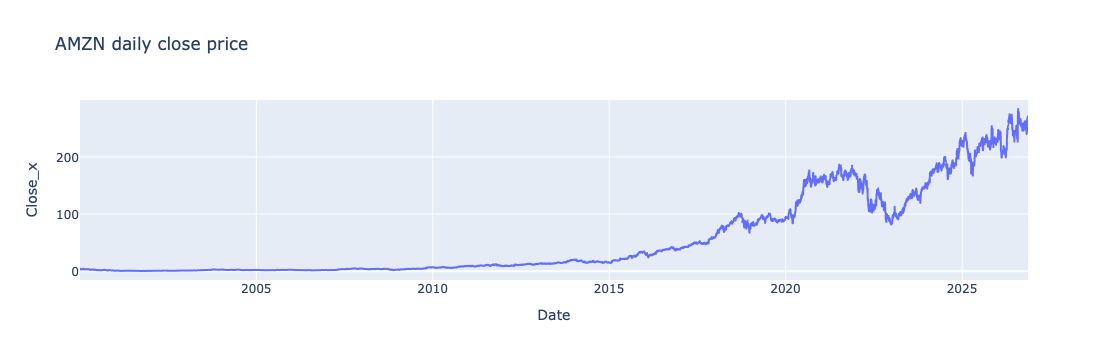

In [46]:
fig = px.line(df_amzn, x="Date", y="Close_x", title='AMZN daily close price')
fig.show()
     

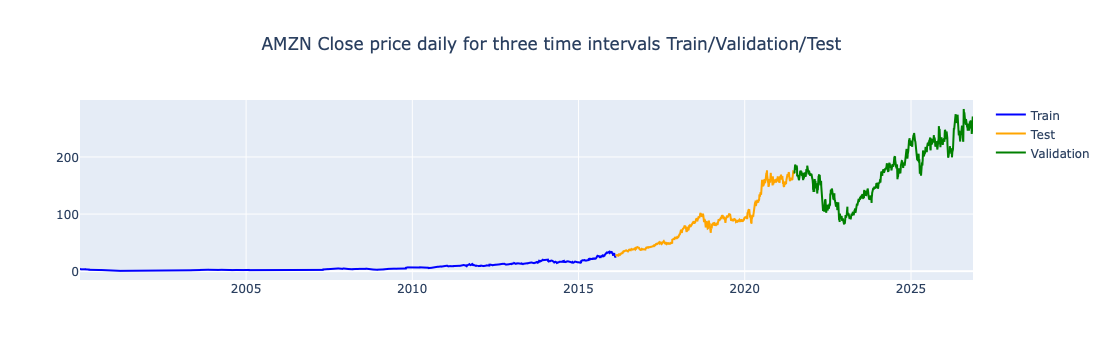

In [47]:
# TRAIN / TEST / VALIDATION split

# Calculate the lengths of each split -- this is not temporal split, but based on the number of observations --> "classic" split with no shuffle
total_length = len(df_amzn)
train_length = int(0.6 * total_length)
test_length = int(0.2 * total_length)
val_length = int(total_length-(train_length+test_length))

# Split the data
train_data = df_amzn.iloc[:train_length]
test_data = df_amzn.iloc[train_length:train_length+test_length]
val_data = df_amzn.iloc[train_length+test_length:]

# Plot the data
fig = px.line(title='AMZN Close price daily for three time intervals Train/Validation/Test')
fig.add_scatter(x=train_data['Date'], y=train_data['Close_x'], mode='lines', name='Train', line=dict(color='blue'))
fig.add_scatter(x=test_data['Date'], y=test_data['Close_x'], mode='lines', name='Test', line=dict(color='orange'))
fig.add_scatter(x=val_data['Date'], y=val_data['Close_x'], mode='lines', name='Validation', line=dict(color='green'))

# Update layout to center the title
fig.update_layout(title=dict(x=0.5))

fig.show()
     


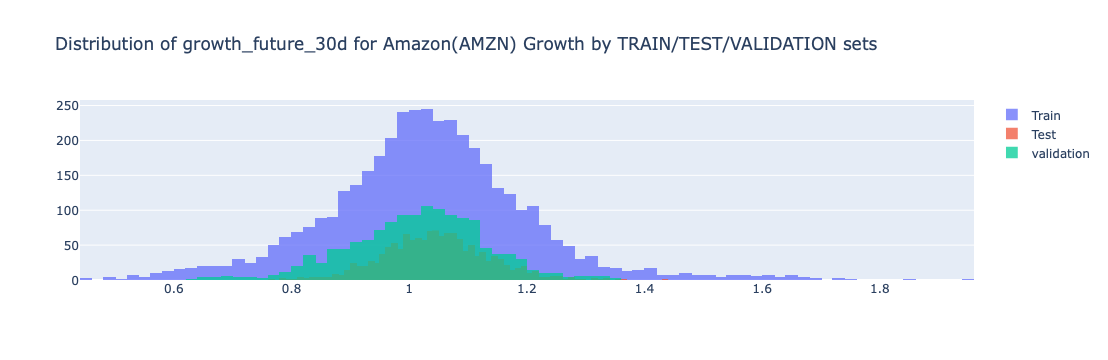

In [48]:
#HIST ON NVDA DATA TRAIN/TEST/VALIDATION
fig = go.Figure()
#Add histograms for each split
fig.add_trace(go.Histogram(x=train_data['growth_future_30d'],name ='Train',opacity = 0.75))
fig.add_trace(go.Histogram(x=test_data['growth_future_30d'],name ='Test',opacity =0.75))
fig.add_trace(go.Histogram(x=val_data['growth_future_30d'],name ='validation',opacity =0.75))
fig.update_layout(barmode ='overlay',title ='Distribution of growth_future_30d for Amazon(AMZN) Growth by TRAIN/TEST/VALIDATION sets' )
fig.update_traces(opacity =0.75)
fig.show()

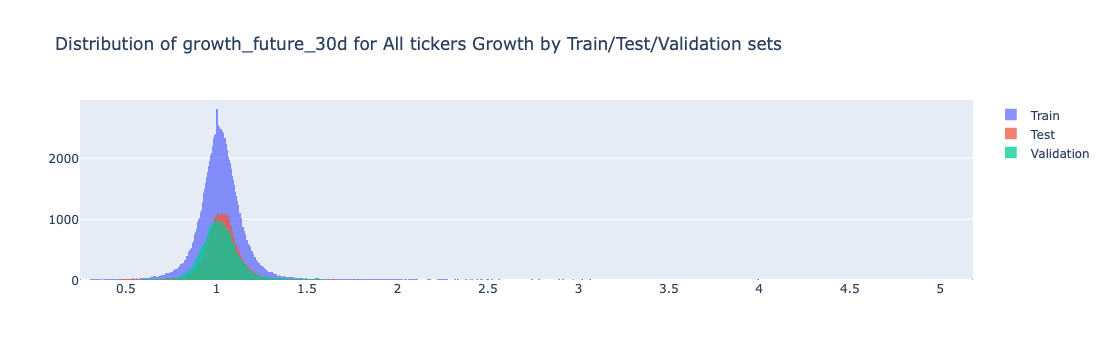

In [49]:
# HIST ON ALL DATA Train/Test/Validation
# there are some outliers and hard co compare the distributions


# Plot the data
fig = go.Figure()

# Add histograms for each split
fig.add_trace(go.Histogram(x=df_with_dummies[df_with_dummies.split=='train']['growth_future_30d'], name='Train', opacity=0.75))
fig.add_trace(go.Histogram(x=df_with_dummies[df_with_dummies.split=='test']['growth_future_30d'], name='Test', opacity=0.75))
fig.add_trace(go.Histogram(x=df_with_dummies[df_with_dummies.split=='validation']['growth_future_30d'], name='Validation', opacity=0.75))

fig.update_layout(barmode='overlay', title='Distribution of growth_future_30d for All tickers Growth by Train/Test/Validation sets')
fig.update_traces(opacity=0.75)

fig.show()
     

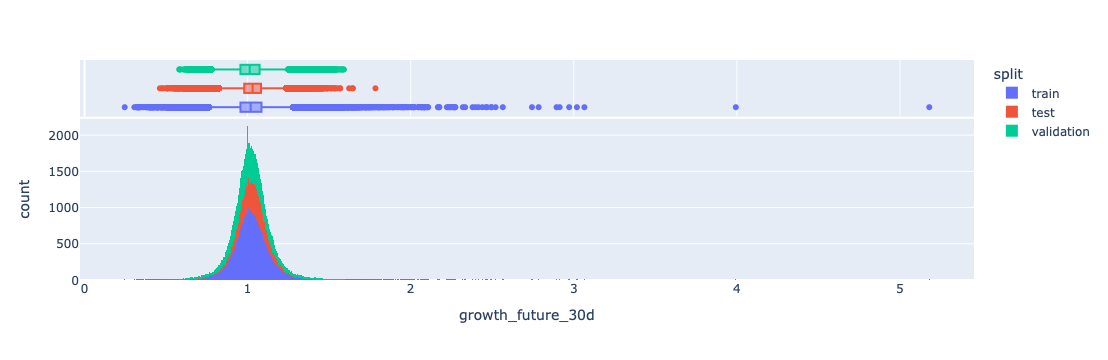

In [50]:
#Assuming df_with_dummies is my dataframe containing the'growth_future_5d' variable and 'split' column
#creating the histogram
fig = px.histogram(new_df,
                   x="growth_future_30d",
                   color = "split",
                   marginal="box"
                  )
fig.show()

In [51]:
new_df.groupby(by='split')['growth_future_30d'].describe()

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,41893.0,1.030950,0.092811,0.461847,0.978988,1.030401,1.082152,1.783610
train,115144.0,1.022372,0.127127,0.246131,0.955917,1.018633,1.084818,5.179687
validation,41928.0,1.017414,0.099381,0.580332,0.955704,1.012669,1.073235,1.590220


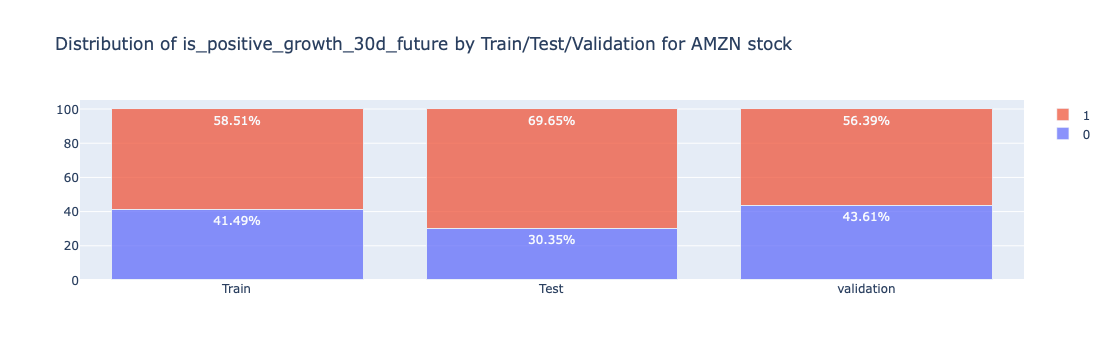

In [52]:
# is_positive_growth_5d_future: ONLY AMZN stock

# Count occurrences of 0 and 1 for each split
train_counts = train_data['is_positive_growth_30d_future'].value_counts(normalize=True)*100
test_counts = test_data['is_positive_growth_30d_future'].value_counts(normalize=True)*100
val_counts = val_data['is_positive_growth_30d_future'].value_counts(normalize=True)*100

# Plot the data
fig = go.Figure()

# # Add stacked bar charts for each split
# fig.add_trace(go.Bar(x=['Train', 'Validation', 'Test'], y=[train_counts[0], val_counts[0], test_counts[0]], name='0'))
# fig.add_trace(go.Bar(x=['Train', 'Validation', 'Test'], y=[train_counts[1], val_counts[1], test_counts[1]], name='1'))


# Add stacked bar charts for each split
fig.add_trace(go.Bar(x=['Train', 'Test', 'validation'], y=[train_counts[0], test_counts[0], val_counts[0]], name='0',
                     text=[f'{count:.2f}%' for count in [train_counts[0], test_counts[0], val_counts[0]]], textposition='auto'))
fig.add_trace(go.Bar(x=['Train', 'Test', 'validation'], y=[train_counts[1], test_counts[1], val_counts[1]], name='1',
                     text=[f'{count:.2f}%' for count in [train_counts[1], test_counts[1], val_counts[1]]], textposition='auto'))


fig.update_layout(barmode='stack', title='Distribution of is_positive_growth_30d_future by Train/Test/Validation for AMZN stock')
fig.update_traces(opacity=0.75)

fig.show()

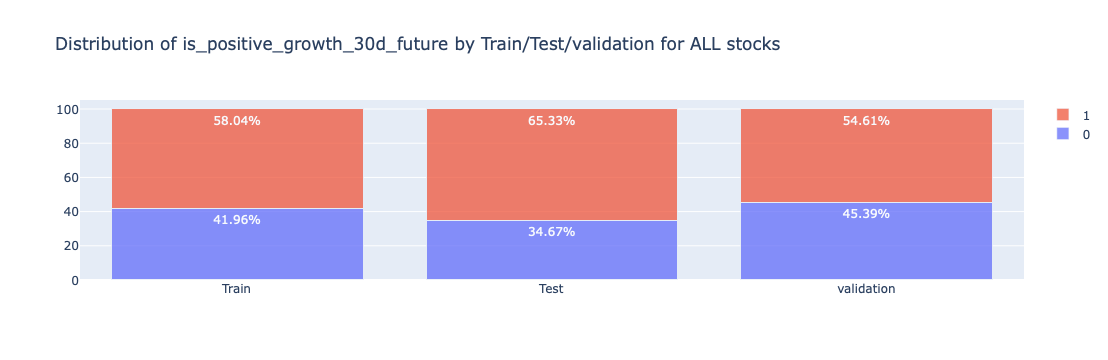

In [53]:
# ALL STOCKS: train/test/validation is more similar

# Count occurrences of 0 and 1 for each split
train_counts = df_with_dummies[df_with_dummies.split=='train']['is_positive_growth_30d_future'].value_counts(normalize=True)*100
test_counts = df_with_dummies[df_with_dummies.split=='test']['is_positive_growth_30d_future'].value_counts(normalize=True)*100
val_counts = df_with_dummies[df_with_dummies.split=='validation']['is_positive_growth_30d_future'].value_counts(normalize=True)*100

# Plot the data
fig = go.Figure()


# Add stacked bar charts for each split
fig.add_trace(go.Bar(x=['Train', 'Test', 'validation'], y=[train_counts[0], test_counts[0], val_counts[0]], name='0',
                     text=[f'{count:.2f}%' for count in [train_counts[0], test_counts[0], val_counts[0]]], textposition='auto'))
fig.add_trace(go.Bar(x=['Train', 'Test', 'validation'], y=[train_counts[1], test_counts[1], val_counts[1]], name='1',
                     text=[f'{count:.2f}%' for count in [train_counts[1], test_counts[1], val_counts[1]]], textposition='auto'))


fig.update_layout(barmode='stack', title='Distribution of is_positive_growth_30d_future by Train/Test/validation for ALL stocks')
fig.update_traces(opacity=0.75)

fig.show()

REVIEWING ALL THE INPUTS AGAIN

In [54]:
# removing the "segmentation" problem (warning message on df performance after many joins and data transformations)
new_df = df_with_dummies.copy()

In [55]:
new_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199925 entries, 3490 to 6052
Columns: 260 entries, Open to split
dtypes: datetime64[ns](2), float64(131), int32(117), int64(5), object(5)
memory usage: 308.9+ MB


In [56]:
new_df.head(1)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,Ticker_SAP,Ticker_SBIN.NS,Ticker_SIE.DE,Ticker_TCS.NS,Ticker_TTE,Ticker_V,ticker_type_EU,ticker_type_INDIA,ticker_type_US,split
3490,35.623621,36.003,33.992295,35.377026,53228400.0,0.0,0.0,MSFT,2000,1,...,0,0,0,0,0,0,0,0,1,train


In [57]:
# time split on train/test/validation: FIXED dates of split, approx. 60%, 20%, 20% split
new_df.groupby(['split'])['Date'].agg({'min','max','count'})

,count,max,min
split,,,
test,41893,2021-07-02,2016-02-17
train,115144,2016-02-16,2000-01-03
validation,42888,2026-11-16,2021-07-05


In [58]:
new_df[TO_PREDICT].head(1)

,growth_future_30d,is_positive_growth_30d_future
3490,0.845576,0


In [59]:
new_df[NUMERICAL + DUMMIES].head(1)

,growth_1d,growth_3d,growth_7d,growth_30d,growth_90d,growth_365d,growth_dax_1d,growth_dax_3d,growth_dax_7d,growth_dax_30d,...,Ticker_RMS.PA,Ticker_SAP,Ticker_SBIN.NS,Ticker_SIE.DE,Ticker_TCS.NS,Ticker_TTE,Ticker_V,ticker_type_EU,ticker_type_INDIA,ticker_type_US
3490,0.998395,0.988341,0.991494,1.372333,1.222951,2.063054,0.970196,0.983855,1.051736,1.134572,...,0,0,0,0,0,0,0,0,0,1


In [60]:
# why does it work?
# compare a vector (pandas.core.series.Series) with scalar 200 ==> element_wise comparison with the number ==> generate a new DataFrame
# (only 5 values)
pd.DataFrame(new_df.cci>200).head()

,cci
3490,False
3491,False
3492,False
3493,False
3494,False


In [61]:
pd.DataFrame(new_df.cci>200).tail()

,cci
6048,False
6049,False
6050,False
6051,False
6052,False


In [62]:
# generating manual predictions
# Let's label all prediction features with prefix "pred"
new_df['pred0_manual_cci'] = (new_df.cci>200).astype(int)
new_df['pred1_manual_prev_g1'] = (new_df.growth_30d>1).astype(int)
new_df['pred2_manual_prev_g1_and_snp'] = ((new_df['growth_30d'] > 1) & (new_df['growth_snp500_30d'] > 1)).astype(int)

In [63]:
new_df[['cci','growth_30d','growth_snp500_30d','pred0_manual_cci','pred1_manual_prev_g1','pred2_manual_prev_g1_and_snp','is_positive_growth_30d_future']].sample(10)




,cci,growth_30d,growth_snp500_30d,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,is_positive_growth_30d_future
2515,-3.943767,1.088516,NaN,0,1,0,0
4547,115.419297,1.088018,NaN,0,1,0,1
2781,95.429750,1.169678,NaN,0,1,0,0
1476,157.233887,0.892220,NaN,0,0,0,0
1026,-23.697789,0.996587,NaN,0,0,0,1
10235,-24.588070,1.026145,NaN,0,1,0,1
1968,-25.520402,1.098113,NaN,0,1,0,1
4632,60.398892,0.910023,NaN,0,0,0,1
4567,128.265527,1.134409,NaN,0,1,0,1
2557,-116.228405,0.910297,NaN,0,0,0,1


In [64]:
PREDICTIONS = [k for k in new_df.keys() if k.startswith('pred')]
PREDICTIONS

['pred0_manual_cci', 'pred1_manual_prev_g1', 'pred2_manual_prev_g1_and_snp']

In [65]:
p = PREDICTIONS[0]
part1 = p.split('_')[0]
print(f'Full column name:{p},only first part:{part1}')

Full column name:pred0_manual_cci,only first part:pred0


In [66]:
# One prediction: do we predict correctly?
new_df['is_correct_prediction'] = (new_df.pred0_manual_cci == new_df.is_positive_growth_30d_future)

In [67]:
new_df[['cci','pred0_manual_cci','is_positive_growth_30d_future','is_correct_prediction']]

,cci,pred0_manual_cci,is_positive_growth_30d_future,is_correct_prediction
3490,26.847900,0,0,True
3491,-34.319518,0,0,True
3492,-97.318543,0,0,True
3493,-169.947134,0,0,True
3494,-142.141749,0,0,True
...,...,...,...,...
6048,143.025415,0,0,True
6049,140.450307,0,0,True
6050,107.554834,0,0,True
6051,85.152691,0,0,True


In [68]:
# checking the  "Precision" : the percentage of "correct" predictions , WHEN we predict "1" (POSITIVE future growth)
filter = (new_df.split=='validation') & (new_df.pred0_manual_cci==1)
new_df[filter].is_correct_prediction.value_counts()

is_correct_prediction
True     584
False    545
Name: count, dtype: int64

In [69]:
# %% of correct predictions : 52%
new_df[filter].is_correct_prediction.value_counts() / len(new_df[filter])

is_correct_prediction
True     0.517272
False    0.482728
Name: count, dtype: float64

In [70]:
del new_df["is_correct_prediction"]

In [71]:
#generating collumns is_correct_
for pred in PREDICTIONS:
    part1 = pred.split('_')[0]#first prefix before('_')
    new_df[f'is_correct_{part1}'] = (new_df[pred] == new_df.is_positive_growth_30d_future).astype(int)

In [72]:
#IS_CORRECT dataset
IS_CORRECT = [k for k in new_df.keys()if k.startswith('is_correct_')]
IS_CORRECT

['is_correct_pred0', 'is_correct_pred1', 'is_correct_pred2']

In [73]:
#completing the dataframe
new_df[PREDICTIONS +IS_CORRECT+['is_positive_growth_30d_future']].sample(5)

,pred0_manual_cci,pred1_manual_prev_g1,pred2_manual_prev_g1_and_snp,is_correct_pred0,is_correct_pred1,is_correct_pred2,is_positive_growth_30d_future
6183,0,1,0,0,1,0,1
3629,0,0,0,0,0,0,1
714,0,0,0,0,0,0,1
5965,0,1,0,0,1,0,1
6522,0,0,0,1,1,1,0


In [74]:
len(new_df[new_df.split == 'validation'])

42888

In [75]:
#Defining precision for all prediction on a Validation dataset(~4 years of trading)
for i, column in enumerate (IS_CORRECT):
    prediction_column = PREDICTIONS[i]
    is_correct_column = column
    filter = (new_df.split == 'validation')&(new_df[prediction_column] == 1)
    print(f'prediction column:{is_correct_column}')
    print(new_df[filter][is_correct_column].value_counts())
    print(new_df[filter][is_correct_column].value_counts()/len(new_df[filter]))

    print('------------')

prediction column:is_correct_pred0
is_correct_pred0
1    584
0    545
Name: count, dtype: int64
is_correct_pred0
1    0.517272
0    0.482728
Name: count, dtype: float64
------------
prediction column:is_correct_pred1
is_correct_pred1
1    13075
0    10996
Name: count, dtype: int64
is_correct_pred1
1    0.543185
0    0.456815
Name: count, dtype: float64
------------
prediction column:is_correct_pred2
Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: float64)
------------


In [76]:
# define "Precision" for ALL predictions on a Test dataset (~4 last years of trading)
for i,column in enumerate(IS_CORRECT):
  prediction_column = PREDICTIONS[i]
  is_correct_column = column
  filter = (new_df.split=='test') & (new_df[prediction_column]==1)
  print(f'Prediction column:{prediction_column} , is_correct_column: {is_correct_column}')
  print(new_df[filter][is_correct_column].value_counts())
  print(new_df[filter][is_correct_column].value_counts()/len(new_df[filter]))

  print('---------')

Prediction column:pred0_manual_cci , is_correct_column: is_correct_pred0
is_correct_pred0
1    792
0    438
Name: count, dtype: int64
is_correct_pred0
1    0.643902
0    0.356098
Name: count, dtype: float64
---------
Prediction column:pred1_manual_prev_g1 , is_correct_column: is_correct_pred1
is_correct_pred1
1    17665
0     9719
Name: count, dtype: int64
is_correct_pred1
1    0.645085
0    0.354915
Name: count, dtype: float64
---------
Prediction column:pred2_manual_prev_g1_and_snp , is_correct_column: is_correct_pred2
Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: float64)
---------


In [77]:
#Advanced [statistical predictions] ARIMA models with 3 parameters(p,q,r)
#setting the 'Date' as the index
df_arima = df_amzn.copy()

df_arima.set_index('Date',inplace=True)
df_arima.head()

#we want to only use time series values and no other features
train_test = df_arima[df_arima.split.isin(['train','test'])]['Close_x']
validation = df_arima[df_arima.split.isin(['validation'])]['Close_x']
#this is needed to make a decision about investing for 5 days
validation_is_positive_future_30d = df_arima[df_arima.split.isin(['validation'])]['is_positive_growth_30d_future']



In [78]:
# !pip install pmdarima
# from pmdarima import auto_arima
     

In [79]:
# Hyper parameters optimization
# # ~ several minutes to run
# # https://miqbalrp.medium.com/exploring-autoarima-in-python-for-multiple-time-series-forecasting-2f3004ba5a49
# # https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html
# # Auto ARIMA model fitting: iterating across params
# best_arima_model = auto_arima(train_validation,
#                    seasonal=False,
#                    trace=True,
#                    start_p=0, start_q=0, # minimum p and q
#                    max_p=12, max_q=12,   # maximum p and q
#                    D=None,               # let model determine 'D'
#                    )
    

In [80]:
# best model specification trained on train_validation
# # (p=6, q=2, r=2)
# best_arima_model.get_params()['order']

# model parameters ("coef" for auto-regression (AR) and moving-average (MA))
# best_arima_model.summary()

In [81]:
#we want to make 918 predictions
len(validation)

1348

In [82]:
#This was used to train the model and obtain the best params
train_test[-1:]

Date
2021-07-02    175.548996
Name: Close_x, dtype: float64

In [83]:
#history as a series and the "last value"(current last known data)
history = [x for x in train_test]
history[-1]

175.5489959716797

In [84]:
#[last day] now need to predict for each value of validation using all available history
validation[-1:]

Date
2026-11-13    266.660004
Name: Close_x, dtype: float64

In [85]:
#slow to predict, cannot quickly predict for all 32 tickers * 918 observations (~30k predictions), Lets have only 1 ticker and these periods to periods to predict:
# will be changing this to 10(1min) or 50(5mins) to run faster
PERIODS_TO_PREDICT = 30



In [86]:
#now we start to predict at day1 of  validation dataframe(WE SEE the adj_close price and predict 5 periods ahead)
df_arima[df_arima.split == 'validation'].head(5)

,Open,High,Low,Close_x,Volume,Dividends,Stock Splits,Ticker,Year,Month,...,Ticker_SAP,Ticker_SBIN.NS,Ticker_SIE.DE,Ticker_TCS.NS,Ticker_TTE,Ticker_V,ticker_type_EU,ticker_type_INDIA,ticker_type_US,split
Date,,,,,,,,,,,,,,,,,,,,,
2021-07-06,176.505493,184.274002,176.449997,183.787003,134896000.0,0.0,0.0,AMZN,2021,7,...,0,0,0,0,0,0,0,0,1,validation
2021-07-07,185.869003,186.710007,183.945496,184.828995,106562000.0,0.0,0.0,AMZN,2021,7,...,0,0,0,0,0,0,0,0,1,validation
2021-07-08,182.177994,187.999496,181.056000,186.570496,103612000.0,0.0,0.0,AMZN,2021,7,...,0,0,0,0,0,0,0,0,1,validation
2021-07-09,186.126007,187.399994,184.669998,185.966995,74964000.0,0.0,0.0,AMZN,2021,7,...,0,0,0,0,0,0,0,0,1,validation
2021-07-12,187.199997,187.864502,184.839493,185.927505,51432000.0,0.0,0.0,AMZN,2021,7,...,0,0,0,0,0,0,0,0,1,validation


In [87]:
#2026 static params,instead of autotuned
#p,q,r = best_arima_model.get_params()['order']
p,q,r = 6,2,2

In [88]:
%%time
# rolling forecast for ARIMA(6,2,2) model
# https://machinelearningmastery.com/arima-for-time-series-forecasting-with-python/


# start from all previous history of train_test
history = [x for x in train_test]
predictions = []
decisions = []
is_correct_decisions = []

tp=0 # true positive
fp=0 # false positive

# walk-forward validation for PERIODS_TO_PREDICT
for t in range(PERIODS_TO_PREDICT):
  current_adj_close = validation.iloc[t] # current adj_close price when we do the prediction
  current_is_future_growth_30d = validation_is_positive_future_30d.iloc[t]

  model = ARIMA(history, order = (p,q,r)) # substitute best parameters AND RETRAIN the model (very expensive)
  model_fit = model.fit()
  output = model_fit.forecast(steps=30) # forecast for 30 periods ahead

  yhat = output[29] # prediction 30 periods ahead

  if yhat > current_adj_close:
    prediction = 1
  else:
    prediction = 0

  is_correct = (prediction==current_is_future_growth_30d).astype(int)

  if prediction == 1:
    if is_correct ==1:
      tp+=1
    else:
      fp+=1

  predictions.append(yhat)

  decisions.append(prediction)
  is_correct_decisions.append(is_correct)
  # Corrected: Add the current actual observation to history for the next iteration
  history.append(current_adj_close)
  # Ensuring enough test data exists to get the actual 30-day ahead value for printing
  actual_30d_ahead = validation.iloc[t + 29] if (t + 29) < len(validation) else np.nan
  print(f'step {t}, current_price = {np.round(current_adj_close,1)}, predicted_30d_ahead={np.round(yhat,1)}, actual_30d_ahead={np.round(actual_30d_ahead,1)}, decision = {prediction}, is_correct = {is_correct} ')





step 0, current_price = 183.8, predicted_30d_ahead=178.6, actual_30d_ahead=164.9, decision = 0, is_correct = 1 
step 1, current_price = 184.8, predicted_30d_ahead=186.4, actual_30d_ahead=162.1, decision = 1, is_correct = 0 
step 2, current_price = 186.6, predicted_30d_ahead=187.9, actual_30d_ahead=160.1, decision = 1, is_correct = 0 
step 3, current_price = 186.0, predicted_30d_ahead=189.8, actual_30d_ahead=159.4, decision = 1, is_correct = 0 
step 4, current_price = 185.9, predicted_30d_ahead=189.9, actual_30d_ahead=160.0, decision = 1, is_correct = 0 
step 5, current_price = 183.9, predicted_30d_ahead=189.6, actual_30d_ahead=163.3, decision = 1, is_correct = 0 
step 6, current_price = 184.1, predicted_30d_ahead=188.1, actual_30d_ahead=165.3, decision = 1, is_correct = 0 
step 7, current_price = 181.6, predicted_30d_ahead=188.4, actual_30d_ahead=165.0, decision = 1, is_correct = 0 
step 8, current_price = 178.7, predicted_30d_ahead=185.9, actual_30d_ahead=165.8, decision = 1, is_corre

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


step 25, current_price = 166.0, predicted_30d_ahead=169.7, actual_30d_ahead=167.2, decision = 1, is_correct = 1 
step 26, current_price = 164.6, predicted_30d_ahead=169.2, actual_30d_ahead=169.0, decision = 1, is_correct = 1 
step 27, current_price = 165.2, predicted_30d_ahead=167.5, actual_30d_ahead=170.8, decision = 1, is_correct = 1 
step 28, current_price = 164.7, predicted_30d_ahead=168.1, actual_30d_ahead=171.3, decision = 1, is_correct = 1 
step 29, current_price = 164.9, predicted_30d_ahead=167.6, actual_30d_ahead=170.3, decision = 1, is_correct = 1 
CPU times: user 2min 30s, sys: 5.42 s, total: 2min 36s
Wall time: 2min 37s


In [89]:
tp

12

In [90]:
fp

17

In [91]:
precision = tp/(tp+fp)
precision

0.41379310344827586

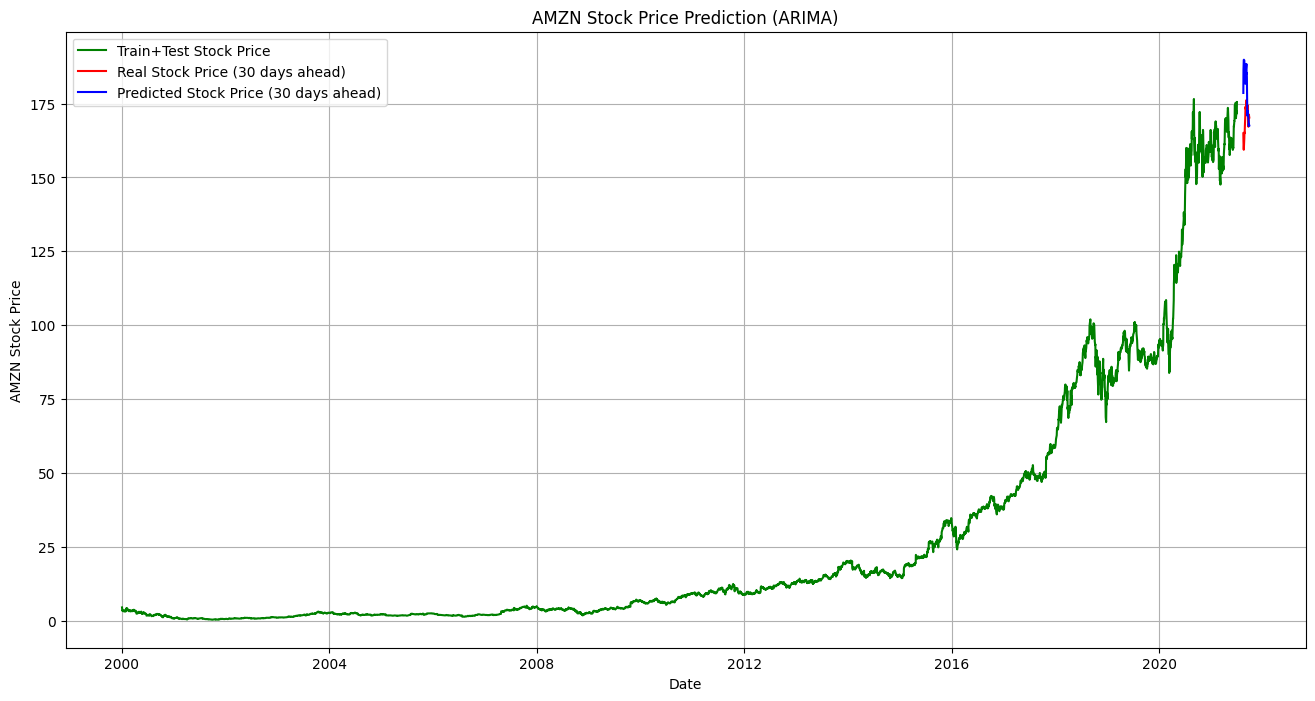

In [92]:
plt.figure(figsize=(16,8))

# Plot train+test history
plt.plot(train_test.index, train_test, color='green', label = 'Train+Test Stock Price')

# Ensure we have enough data in 'validation' for the 30-day ahead forecasts
# We are forecasting 30 days ahead. So the predictions[t] corresponds to validation.iloc[t+29]
# The actual prices to compare against are validation.iloc[29 : PERIODS_TO_PREDICT + 29]
start_idx_for_plot = 29
end_idx_for_plot = PERIODS_TO_PREDICT + 29

if end_idx_for_plot <= len(validation):
    actual_forecast_dates = validation.index[start_idx_for_plot : end_idx_for_plot]
    actual_forecast_values = validation.iloc[start_idx_for_plot : end_idx_for_plot]

    # Plot actual validation prices for the forecast horizon (30 days ahead)
    plt.plot(actual_forecast_dates, actual_forecast_values, color = 'red', label = 'Real Stock Price (30 days ahead)')

    # Plot predicted prices (30 days ahead)
    plt.plot(actual_forecast_dates, predictions, color = 'blue', label = 'Predicted Stock Price (30 days ahead)')
else:
    print(f"Not enough data in 'validation' for {PERIODS_TO_PREDICT} 30-day ahead predictions to align for plotting.")
    print(f"'validation' length: {len(validation)}, required length for plotting {end_idx_for_plot}")

plt.title('AMZN Stock Price Prediction (ARIMA)')
plt.xlabel('Date')
plt.ylabel('AMZN Stock Price')
plt.legend()
plt.grid(True)
plt.show()
     
